## 1. Load the Cleaned Dataset

In [2]:
import pandas as pd

file_path = 'dataset/Bipolar_cleaned.csv'
df_subset = pd.read_csv(file_path)

display(df_subset.head())


,age,gender,marital_status,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,...,substance_alcohol,substance_cannabis,ever_been_treated_with_antipsychotics,rate_response_to_lithium_treatment,ect_recieved,index_episode_episode_at_presentation_to_nimhans,ever_been_treated_with_anticonvulsants,ever_been_treated_with_lithium,antipsychotic,education_standard
0,50.0,Male,Married,17.0,11.0,395.6,41.5,2.0,7.0,2.0,...,Unchecked,Unchecked,Yes,8.0,No,Mania without psychotic symptoms,Yes,Yes,Chlorpromazine,Primary/Secondary
1,67.1,Male,Married,38.6,6.0,342.2,13.0,0.0,4.0,0.0,...,Unchecked,Unchecked,Yes,8.0,No,Mania with psychotic symptoms,No,Yes,NaN,Other/Unknown
2,48.1,Male,Married,20.3,7.0,333.6,7.0,0.0,6.0,0.0,...,Unchecked,Unchecked,Yes,10.0,Yes,Mania with psychotic symptoms,No,Yes,Chlorpromazine,Undergraduate
3,58.1,Male,Married,30.2,6.0,334.7,7.0,0.0,4.0,0.0,...,Unchecked,Unchecked,Yes,9.0,No,Mania with psychotic symptoms,No,Yes,Chlorpromazine,Illiterate
4,49.1,Female,Married,21.2,11.0,335.2,16.0,0.0,9.0,0.0,...,Unchecked,Unchecked,Yes,9.0,Yes,Mania with psychotic symptoms,No,Yes,Chlorpromazine,Other/Unknown


In [3]:
categorical_cols = df_subset.select_dtypes(
    include=["object", "category", "str"]
).columns.to_list()

numerical_cols = df_subset.select_dtypes(
    include=["int64", "float64"]
).columns.to_list()

## 2. Univariate Analysis (One Variable at a Time) BEFORE Imputation and Duplicate Removal


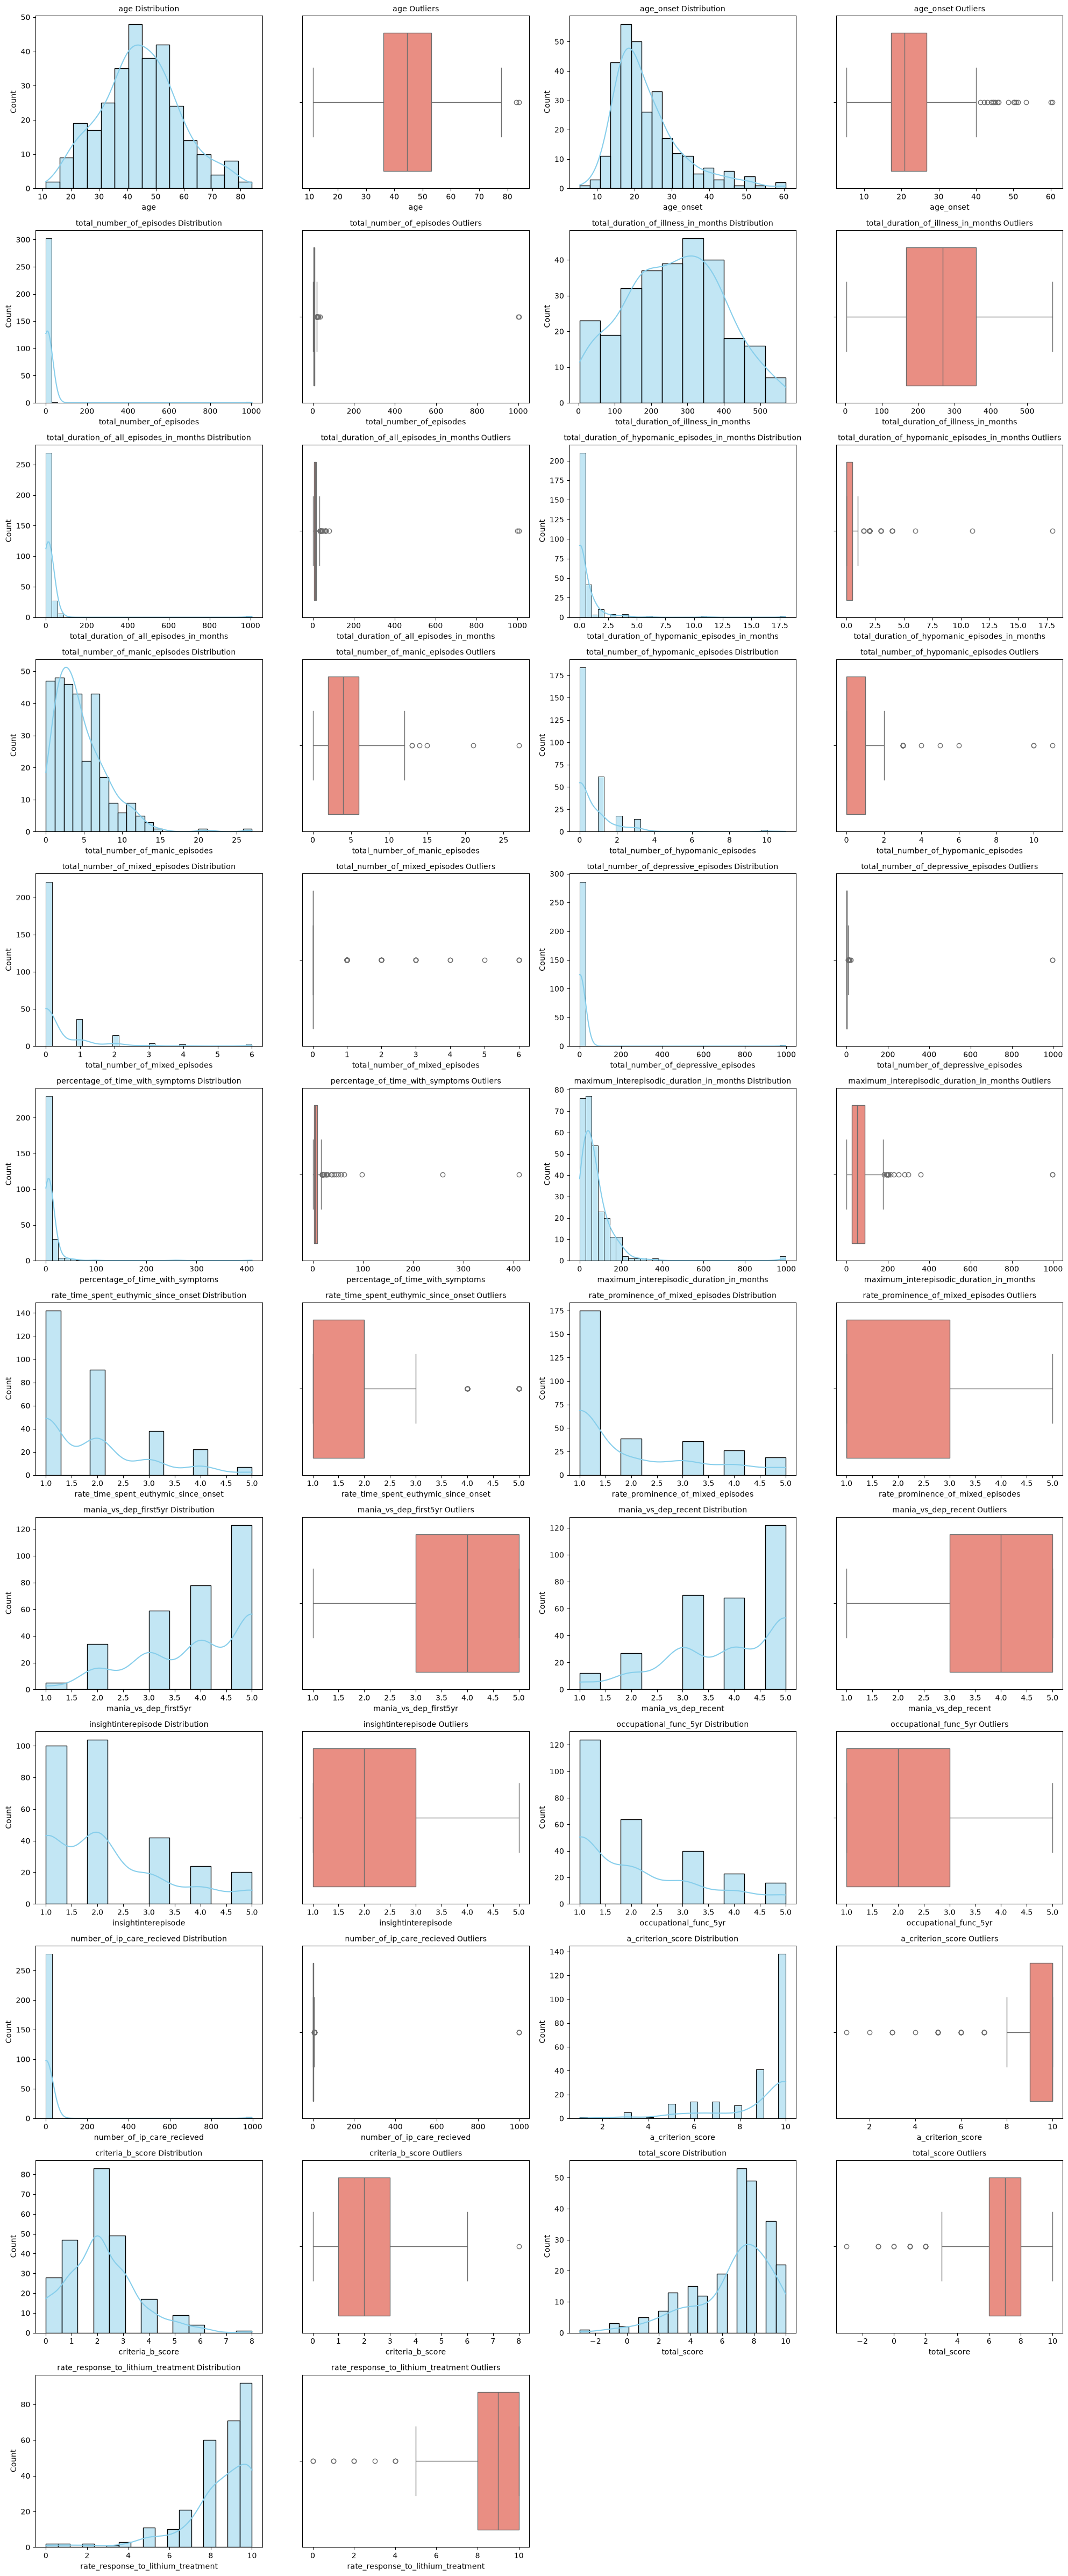

Skipping 0 categorical columns due to high cardinality (>15 unique values).


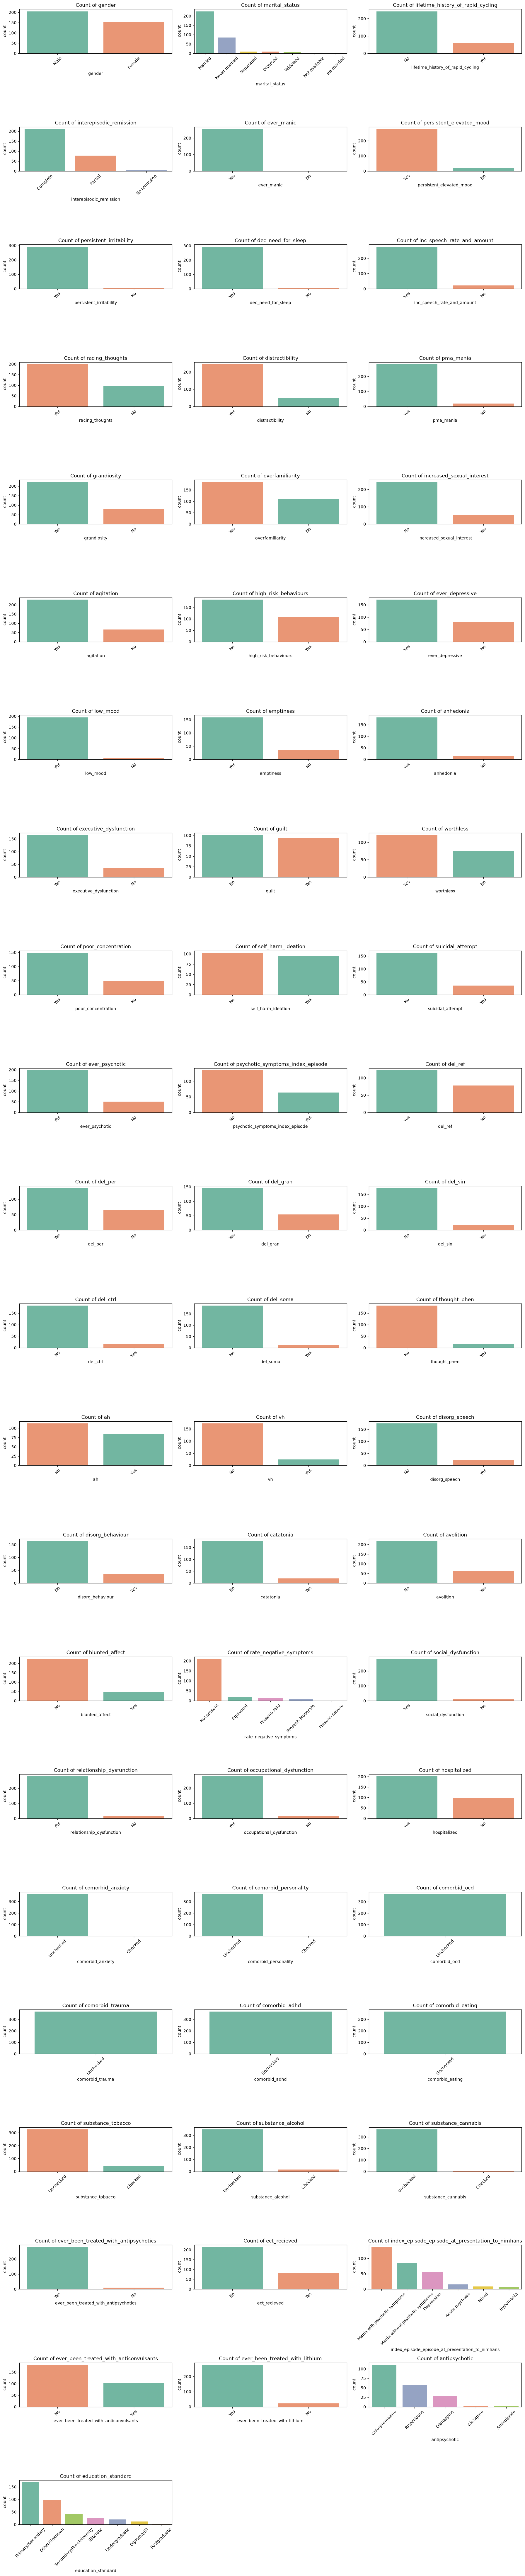

In [4]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# --- NUMERICAL DISTRIBUTIONS (Grid Layout) ---
# We will plot 4 variables (8 subplots total) per row block to save vertical scrolling space
num_plots = len(numerical_cols)
cols_per_row = 2  # 2 variables per row (each getting a Hist and a Boxplot)
rows = math.ceil(num_plots / cols_per_row)

fig, axes = plt.subplots(rows, cols_per_row * 2, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    # Skip if the column is entirely null (boxplot cannot be drawn)
    if df_subset[col].dropna().empty:
        # Hide the corresponding subplots if they exist
        if (i * 2) < len(axes):
            fig.delaxes(axes[i * 2])
        if (i * 2 + 1) < len(axes):
            fig.delaxes(axes[i * 2 + 1])
        continue

    idx_hist = i * 2
    idx_box = i * 2 + 1

    # Histogram
    sns.histplot(df_subset[col], kde=True, ax=axes[idx_hist], color='skyblue')
    axes[idx_hist].set_title(f'{col} Distribution', fontsize=10)

    # Boxplot
    sns.boxplot(x=df_subset[col], ax=axes[idx_box], color='salmon')
    axes[idx_box].set_title(f'{col} Outliers', fontsize=10)

# Hide any leftover empty subplots in the grid
for j in range(num_plots * 2, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


# --- CATEGORICAL COUNTS (Filtered Grid Layout) ---
# Filter out text/ID columns with more than 15 unique values to avoid messy charts
clean_categorical_cols = [col for col in categorical_cols if df_subset[col].nunique() <= 15]
print(f"Skipping {len(categorical_cols) - len(clean_categorical_cols)} categorical columns due to high cardinality (>15 unique values).")

cat_plots = len(clean_categorical_cols)
cat_cols_per_row = 3
cat_rows = math.ceil(cat_plots / cat_cols_per_row)

if cat_plots > 0:
    fig, axes = plt.subplots(cat_rows, cat_cols_per_row, figsize=(18, cat_rows * 4))
    axes = axes.flatten()

    for i, col in enumerate(clean_categorical_cols):
        # Setting hue=col and legend=False satisfies the new Seaborn requirements
        sns.countplot(
            data=df_subset,
            x=col,
            order=df_subset[col].value_counts().index,
            ax=axes[i],
            hue=col,
            palette='Set2',
            legend=False
        )
        axes[i].set_title(f'Count of {col}', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45)


    # Hide leftover subplots
    for j in range(cat_plots, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

## 3. Remove duplicate rows

In [5]:
all_duplicates = df_subset.duplicated().sum()
print(all_duplicates)

25


In [6]:
#Identifying and removing duplicate rows
print("Initial number of rows:", len(df_subset))
df_subset.drop_duplicates(inplace=True)
print("Number of rows after removing duplicates:", len(df_subset))

Initial number of rows: 367
Number of rows after removing duplicates: 342


## 4. Missing value Imputation

In [7]:
df_imputed = df_subset

#### using MICE imputation for numerical columns

In [8]:
if "criteria_b_score" in numerical_cols:
    numerical_cols.remove("criteria_b_score")
    print("[criteria_b_score] feature is found and removed from MICE imputation")

[criteria_b_score] feature is found and removed from MICE imputation


In [9]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

mice_imputer = IterativeImputer(random_state=42)

df_imputed[numerical_cols] = mice_imputer.fit_transform(df_subset[numerical_cols])
numerical_cols.append("criteria_b_score")

print("Missing values after MICE imputation for numerical columns:")
print(df_imputed[numerical_cols].isnull().sum())

Missing values after MICE imputation for numerical columns:
age                                                 0
age_onset                                           0
total_number_of_episodes                            0
total_duration_of_illness_in_months                 0
total_duration_of_all_episodes_in_months            0
total_duration_of_hypomanic_episodes_in_months      0
total_number_of_manic_episodes                      0
total_number_of_hypomanic_episodes                  0
total_number_of_mixed_episodes                      0
total_number_of_depressive_episodes                 0
percentage_of_time_with_symptoms                    0
maximum_interepisodic_duration_in_months            0
rate_time_spent_euthymic_since_onset                0
rate_prominence_of_mixed_episodes                   0
mania_vs_dep_first5yr                               0
mania_vs_dep_recent                                 0
insightinterepisode                                 0
occupational_func_5yr 

/home/abhajkhan/.local/lib/python3.12/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


#### using Predictive Mean Matching (PMM) for `criteria_b_score`

In [10]:
from scipy import stats
import pandas as pd
import numpy as np

results = []

for col in categorical_cols:
    # only use rows where both criteria_b_score and this categorical column are present
    valid = df_imputed[[col, 'criteria_b_score']].dropna()

    if valid[col].nunique() < 2 or len(valid) < 10:
        continue  # skip columns with no variation or too little data

    groups = [valid.loc[valid[col] == level, 'criteria_b_score'] for level in valid[col].unique()]

    # Kruskal-Wallis handles both binary and multi-level, and doesn't assume normality
    stat, p_value = stats.kruskal(*groups)

    results.append({'column': col, 'kruskal_stat': stat, 'p_value': p_value, 'n_valid': len(valid)})

results_df = pd.DataFrame(results).sort_values('p_value')
print(results_df.to_string())

                                              column  kruskal_stat   p_value  n_valid
5                            persistent_irritability      7.799306  0.005227      229
32                                          del_ctrl      7.297802  0.006904      159
9                                    distractibility      7.141468  0.007532      226
24                                self_harm_ideation      6.586487  0.010276      153
28                                           del_ref      5.789641  0.016121      162
4                           persistent_elevated_mood      5.551336  0.018467      228
23                                poor_concentration      4.253587  0.039168      153
22                                         worthless      4.044361  0.044319      151
21                                             guilt      3.849783  0.049752      151
56                                education_standard     11.594831  0.071643      238
53            ever_been_treated_with_anticonvulsants  

In [11]:
# Bonferroni-style guard against false positives given many tests
alpha = 0.05 / len(results_df)  # conservative correction for multiple comparisons

significant_predictors = results_df[results_df['p_value'] < alpha]
print(f"\n{len(significant_predictors)} columns significantly associated with criteria_b_score:")
print(significant_predictors[['column', 'p_value']])


0 columns significantly associated with criteria_b_score:
Empty DataFrame
Columns: [column, p_value]
Index: []


In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OrdinalEncoder

# use only rows where criteria_b_score is observed (not yet imputed)
train_data = df_imputed.dropna(subset=['criteria_b_score']).copy()

X_cat = train_data[categorical_cols].copy()
# encode categoricals as integers (RF handles this fine, it's just splits)
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_cat_encoded = encoder.fit_transform(X_cat.astype(str))

y = train_data['criteria_b_score']

rf = RandomForestRegressor(n_estimators=300, random_state=42, max_depth=5)
rf.fit(X_cat_encoded, y)

importance_df = pd.DataFrame({
    'column': categorical_cols,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print(importance_df.head(15))

                                              column  importance
6                            persistent_irritability    0.107843
57             ever_been_treated_with_antipsychotics    0.078741
10                                   distractibility    0.065047
33                                          del_ctrl    0.061386
60            ever_been_treated_with_anticonvulsants    0.039369
63                                education_standard    0.035916
59  index_episode_episode_at_presentation_to_nimhans    0.031199
25                                self_harm_ideation    0.029400
41                                         avolition    0.028778
62                                     antipsychotic    0.027835
2                  lifetime_history_of_rapid_cycling    0.024783
31                                          del_gran    0.023849
27                                    ever_psychotic    0.023691
3                            interepisodic_remission    0.022618
29                       

In [13]:
# Take the union of top statistical hits and top RF importances
top_kruskal = set(significant_predictors['column'])
top_rf = set(importance_df.head(15)['column'])

final_predictors = list(top_kruskal | top_rf)
print(f"Final predictor set ({len(final_predictors)} columns):")
print(final_predictors)

Final predictor set (15 columns):
['antipsychotic', 'del_gran', 'interepisodic_remission', 'del_ctrl', 'ever_psychotic', 'del_ref', 'ever_been_treated_with_antipsychotics', 'persistent_irritability', 'distractibility', 'avolition', 'lifetime_history_of_rapid_cycling', 'ever_been_treated_with_anticonvulsants', 'education_standard', 'self_harm_ideation', 'index_episode_episode_at_presentation_to_nimhans']


In [14]:
# !pip install miceforest

In [15]:
# pip install "lightgbm>=4.0.0,<4.7.0"


Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3.12 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [16]:
import lightgbm 
print(lightgbm.__version__)
    
import miceforest
print(miceforest.__version__)

4.6.0
6.0.5


In [17]:
# PMM MICE imputation for 'criteria'_b_score' based on selected 15 categorical features(final_predictors) + numerical_cols
import miceforest as mf

final_predictors = ['antipsychotic', 'del_gran', 'interepisodic_remission', 'del_ctrl', 'ever_psychotic', 'del_ref', 'ever_been_treated_with_antipsychotics', 'persistent_irritability', 'distractibility', 'avolition', 'lifetime_history_of_rapid_cycling', 'ever_been_treated_with_anticonvulsants', 'education_standard', 'self_harm_ideation', 'index_episode_episode_at_presentation_to_nimhans']

# 1. Reset your index
df_imputed = df_imputed.reset_index(drop=True)

# 2. Fix hidden infinity values in numerical columns
df_imputed.replace([np.inf, -np.inf], np.nan, inplace=True)

full_input = df_imputed[numerical_cols + final_predictors].copy()

# 3. Handle object & category fields safely
obj_cols = full_input.select_dtypes(include=['object', 'str']).columns
for col in obj_cols:
    full_input[col] = full_input[col].astype('category')

# Crucial: Drop unused category levels that screw up tree distributions
for col in full_input.select_dtypes(include=['category']).columns:
    full_input[col] = full_input[col].cat.remove_unused_categories()

# Initialize the kernel safely
# kernel expects a pandas DataFrame with your numeric columns
kernel = mf.ImputationKernel(
    full_input,                      # your dataframe with missing values (pre-imputation)
    variable_schema={
        'criteria_b_score': [c for c in full_input.columns if c != 'criteria_b_score'],
        'a_criterion_score': [c for c in full_input.columns if c != 'a_criterion_score'],
    },
    num_datasets=1,
    mean_match_candidates=5, # PMM: number of donor candidates to sample from
    random_state=42
)

kernel.mice(
    iterations=5,
    min_data_in_leaf=15,
    cat_smooth=10.0
)

completed_numeric = kernel.complete_data(dataset=0)

# 4. Write ONLY criteria_b_score back into df_imputed — categorical cols remain untouched
df_imputed['criteria_b_score'] = completed_numeric['criteria_b_score']

df_imputed['criteria_b_score'] = df_imputed['criteria_b_score'].round()

print(df_imputed['criteria_b_score'].describe())
print(df_imputed['criteria_b_score'].value_counts().sort_index())
# confirm min >= 0 and max <= 8, and all values are whole numbers

count    342.000000
mean       2.149123
std        1.271611
min        0.000000
25%        1.000000
50%        2.000000
75%        3.000000
max        8.000000
Name: criteria_b_score, dtype: float64
criteria_b_score
0.0     30
1.0     64
2.0    139
3.0     67
4.0     25
5.0     12
6.0      4
8.0      1
Name: count, dtype: int64


#### imputing Categorical features

In [18]:
df_imputed = df_imputed.replace("Unknown", np.nan).copy()

# 1. Confirm the correct gatekeeper column with real crosstabs first
candidate_parents = ['ever_psychotic', 'psychotic_symptoms_index_episode']
skip_logic_map = {
    'del_ref':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_per':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_gran':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_sin':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_ctrl':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_soma':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'thought_phen':       {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'ah':                 {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'vh':                 {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'catatonia':          {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'disorg_speech':      {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'disorg_behaviour':   {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'avolition':          {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'blunted_affect':     {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'rate_negative_symptoms': {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
}

for child_col in skip_logic_map.keys():
    print(f"\n=== {child_col} ===")
    for parent in candidate_parents:
        ct = pd.crosstab(df_imputed[parent], df_imputed[child_col].isna())
        print(f"vs {parent}:\n{ct}\n")


=== del_ref ===
vs ever_psychotic:
del_ref         False  True 
ever_psychotic              
No                  1     50
Yes               195      2

vs psychotic_symptoms_index_episode:
del_ref                           False  True 
psychotic_symptoms_index_episode              
No                                   83     52
Yes                                  58      6


=== del_per ===
vs ever_psychotic:
del_per         False  True 
ever_psychotic              
No                  1     50
Yes               196      1

vs psychotic_symptoms_index_episode:
del_per                           False  True 
psychotic_symptoms_index_episode              
No                                   83     52
Yes                                  58      6


=== del_gran ===
vs ever_psychotic:
del_gran        False  True 
ever_psychotic              
No                  1     50
Yes               195      2

vs psychotic_symptoms_index_episode:
del_gran                          False  True 
psyc

In [19]:
# 2. Fix skip_logic_map's parent column based on what step 1 shows
skip_logic_map = {
    'del_ref':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_per':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_gran':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_sin':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_ctrl':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_soma':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'thought_phen':       {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'ah':                 {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'vh':                 {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'catatonia':          {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'disorg_speech':      {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'disorg_behaviour':   {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    # avolition, blunted_affect, rate_negative_symptoms removed —
    # not conditionally missing on psychosis history; handle their
    # NaNs with standard (non-skip-logic) imputation instead
}

In [20]:
for col in categorical_cols:    df_imputed[col] = df_imputed[col].astype('category')

# 3. Apply recoding BEFORE any "Unknown" fill
for child_col, rule in skip_logic_map.items():
    parent_col = rule['parent']
    condition = (df_imputed[parent_col] == 'No') & (df_imputed[child_col].isna())
    n_recoded = condition.sum()
    if 'No' not in df_imputed[child_col].cat.categories:
        df_imputed[child_col] = df_imputed[child_col].cat.add_categories('No')
    df_imputed.loc[condition, child_col] = 'No'
    print(f"{child_col}: recoded {n_recoded} rows from NaN → 'No' based on {parent_col}=='No'")

del_ref: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
del_per: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
del_gran: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
del_sin: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
del_ctrl: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
del_soma: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
thought_phen: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
ah: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
vh: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
catatonia: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
disorg_speech: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
disorg_behaviour: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'


In [21]:
# 4. Check genuine residual missingness
remaining_missing = df_imputed[list(skip_logic_map.keys())].isna().sum()
print(remaining_missing[remaining_missing > 0])

del_ref             92
del_per             91
del_gran            92
del_sin             94
del_ctrl            95
del_soma            95
thought_phen        95
ah                  95
vh                  95
catatonia           95
disorg_speech       95
disorg_behaviour    94
dtype: int64


In [22]:
# 5. Only now fill true leftover missingness (small, by design) with "Unknown" or proper imputation
for col in categorical_cols:
    if 'Unknown' not in df_imputed[col].cat.categories:
        df_imputed[col] = df_imputed[col].cat.add_categories('Unknown')
    df_imputed[col] = df_imputed[col].fillna("Unknown")

In [23]:
# Updated numerical and categorical columns count
print(f"Updated categorical column count: {len(categorical_cols)}")
print(f"Updated numerical column count: {len(numerical_cols)}")

Updated categorical column count: 64
Updated numerical column count: 23


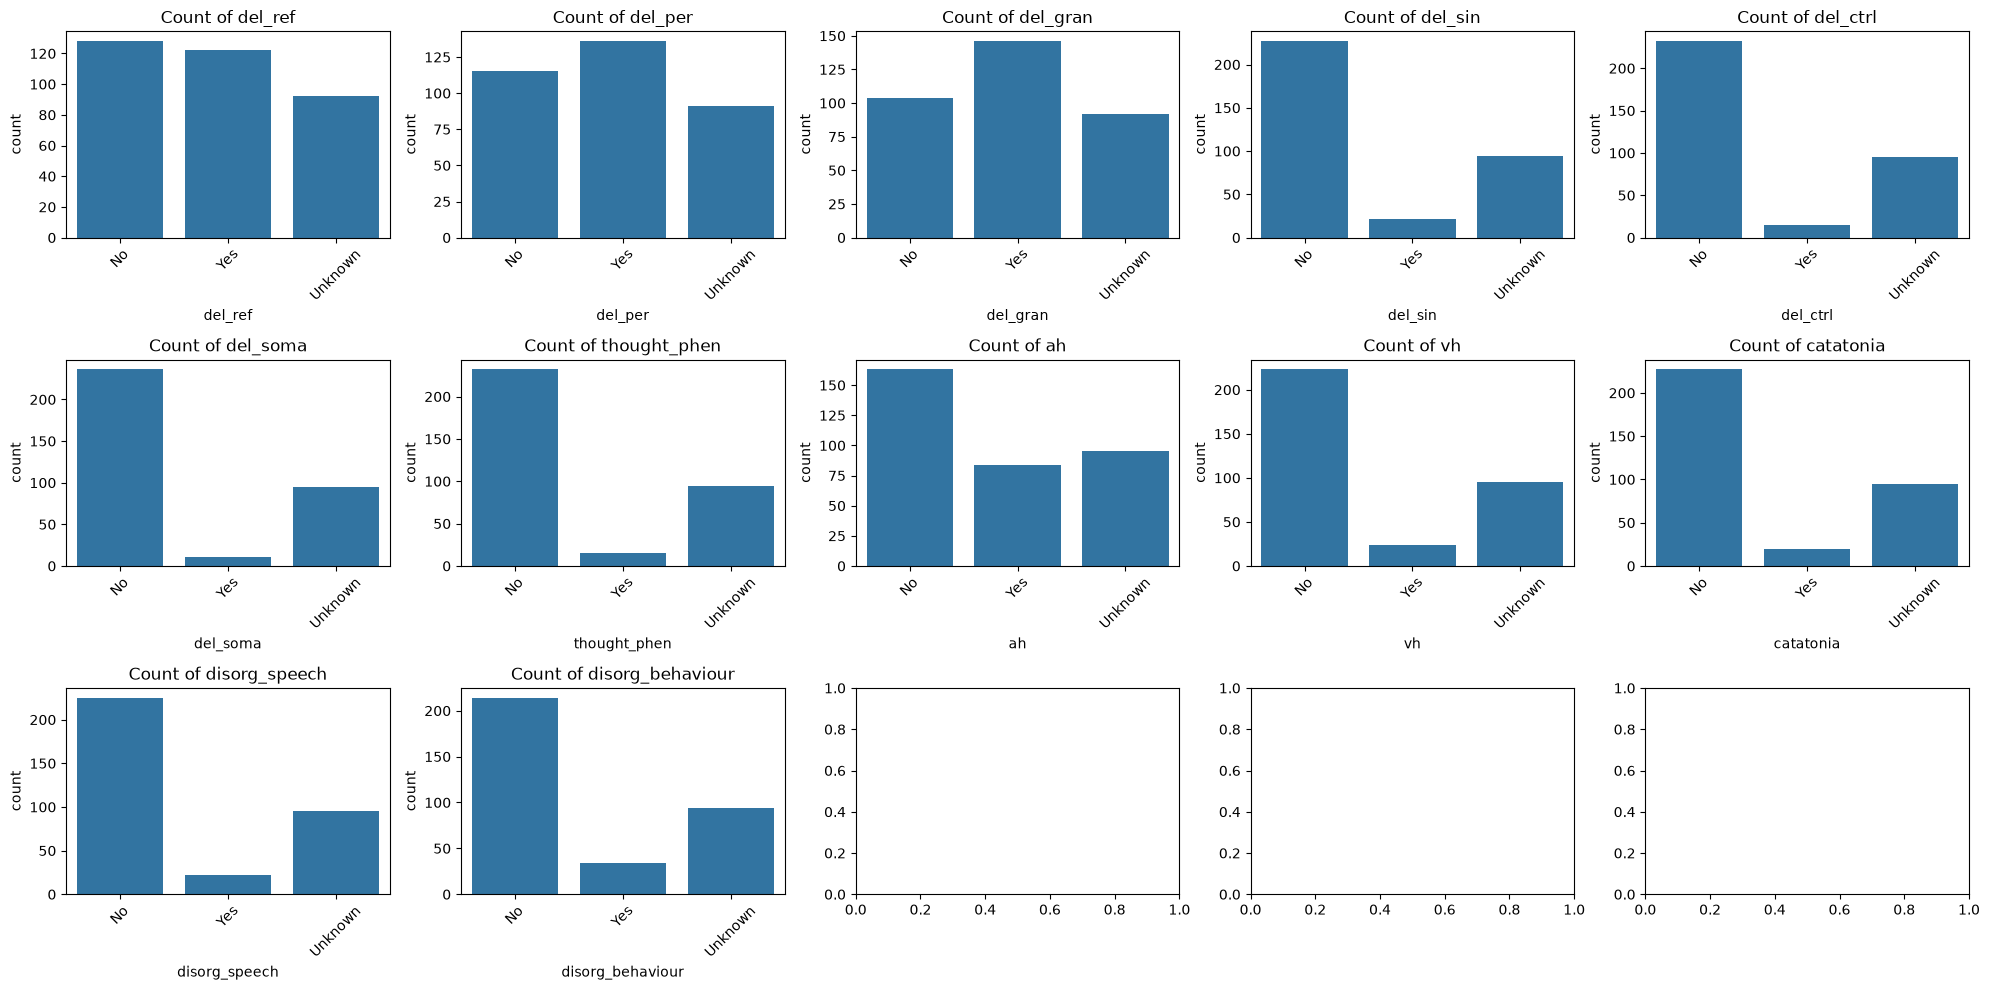

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 5, figsize=(20, 10))
for ax, col in zip(axes.flat, list(skip_logic_map.keys())):
    sns.countplot(x=df_imputed[col], ax=ax)
    ax.set_title(f'Count of {col}')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 5. Univariate Analysis (One Variable at a Time) AFTER Imputation and Duplicate Removal



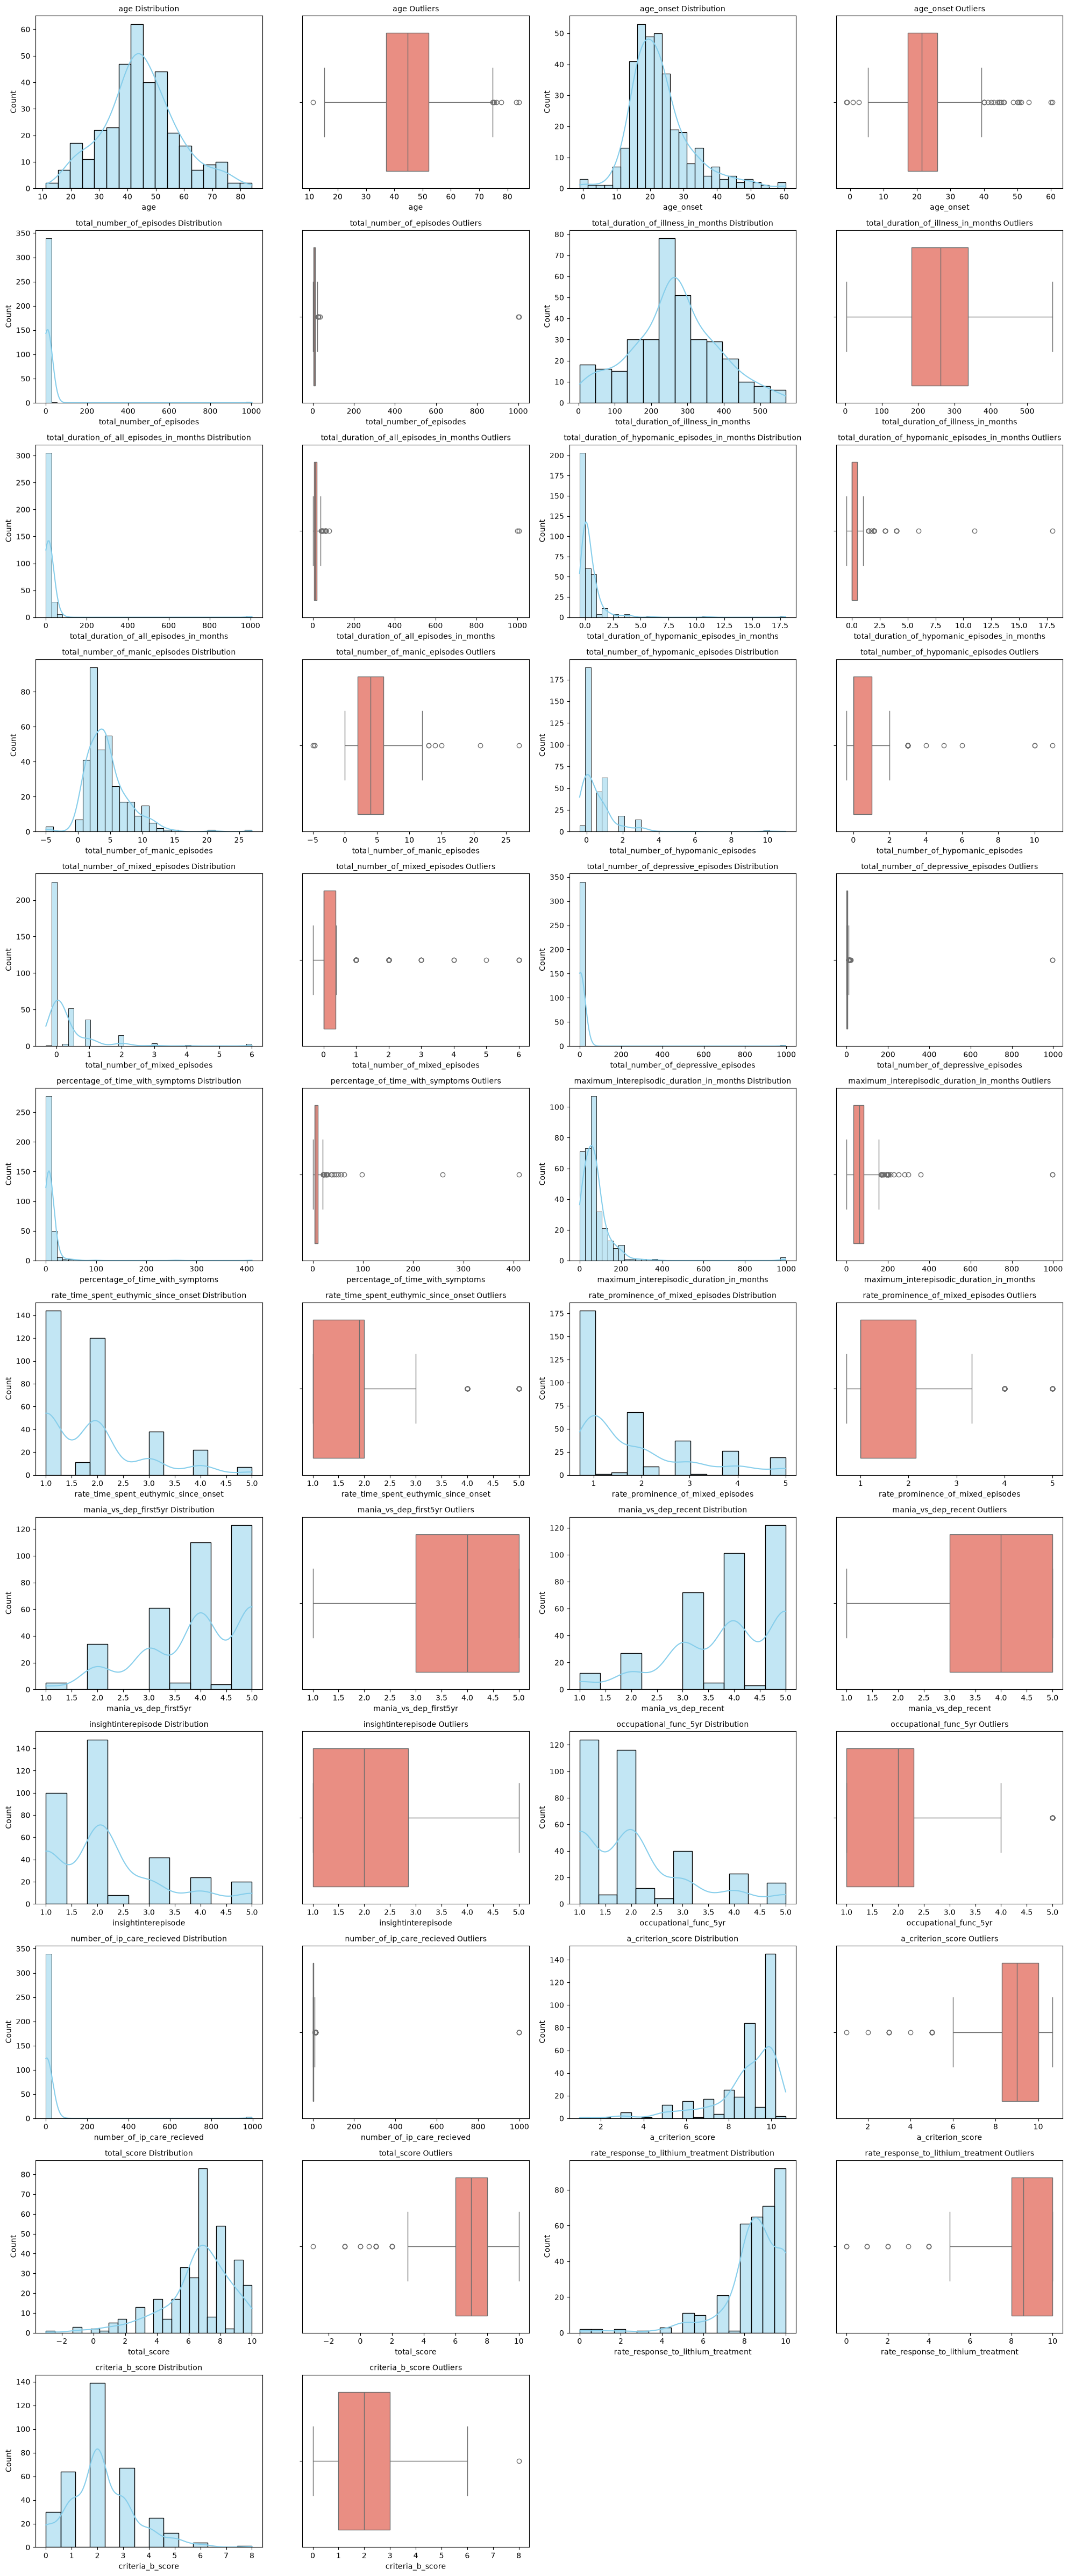

Skipping 0 categorical columns due to high cardinality (>15 unique values).


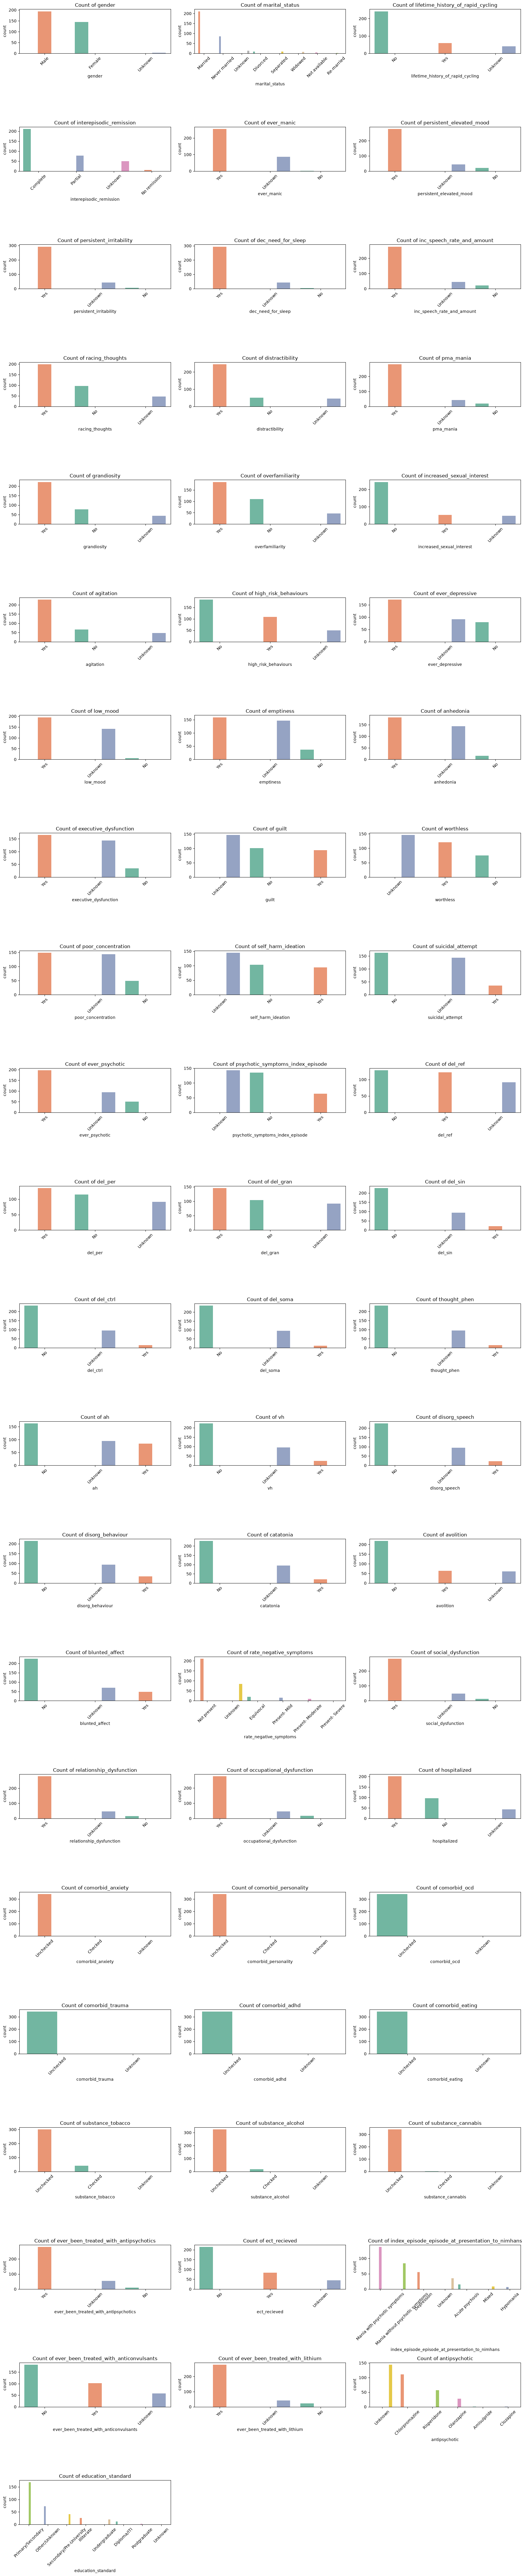

In [27]:
import math

# --- NUMERICAL DISTRIBUTIONS (Grid Layout) ---
# We will plot 4 variables (8 subplots total) per row block to save vertical scrolling space
num_plots = len(numerical_cols)
cols_per_row = 2  # 2 variables per row (each getting a Hist and a Boxplot)
rows = math.ceil(num_plots / cols_per_row)

fig, axes = plt.subplots(rows, cols_per_row * 2, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    # Skip if the column is entirely null (boxplot cannot be drawn)
    if df_subset[col].dropna().empty:
        # Hide the corresponding subplots if they exist
        if (i * 2) < len(axes):
            fig.delaxes(axes[i * 2])
        if (i * 2 + 1) < len(axes):
            fig.delaxes(axes[i * 2 + 1])
        continue

    idx_hist = i * 2
    idx_box = i * 2 + 1

    # Histogram
    sns.histplot(df_imputed[col], kde=True, ax=axes[idx_hist], color='skyblue')
    axes[idx_hist].set_title(f'{col} Distribution', fontsize=10)

    # Boxplot
    sns.boxplot(x=df_imputed[col], ax=axes[idx_box], color='salmon')
    axes[idx_box].set_title(f'{col} Outliers', fontsize=10)

# Hide any leftover empty subplots in the grid
for j in range(num_plots * 2, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


# --- CATEGORICAL COUNTS (Filtered Grid Layout) ---
# Filter out text/ID columns with more than 15 unique values to avoid messy charts
clean_categorical_cols = [col for col in categorical_cols if df_imputed[col].nunique() <= 15]
print(f"Skipping {len(categorical_cols) - len(clean_categorical_cols)} categorical columns due to high cardinality (>15 unique values).")

cat_plots = len(clean_categorical_cols)
cat_cols_per_row = 3
cat_rows = math.ceil(cat_plots / cat_cols_per_row)

if cat_plots > 0:
    fig, axes = plt.subplots(cat_rows, cat_cols_per_row, figsize=(18, cat_rows * 4))
    axes = axes.flatten()

    for i, col in enumerate(clean_categorical_cols):
        # Setting hue=col and legend=False satisfies the new Seaborn requirements
        sns.countplot(
            data=df_imputed,
            x=col,
            order=df_imputed[col].value_counts().index,
            ax=axes[i],
            hue=col,
            palette='Set2',
            legend=False
        )
        axes[i].set_title(f'Count of {col}', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45)


    # Hide leftover subplots
    for j in range(cat_plots, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


## 6. Feature Transformation

### minmax scalar

In [28]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler

# Let's try MinMaxScaler as an alternative to StandardScaler
Bipolar_preprocessed_minmax = df_imputed.copy()

# 1. Identify categorical columns (same as before)
cols_one_hot_encode_minmax = Bipolar_preprocessed_minmax.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

# 2. Apply One-Hot Encoding (same as before)
if cols_one_hot_encode_minmax:
    print("Applying One-Hot Encoding to (for MinMaxScaler demo):")
    print(cols_one_hot_encode_minmax)
    Bipolar_preprocessed_minmax = pd.get_dummies(
        Bipolar_preprocessed_minmax,
        columns=cols_one_hot_encode_minmax,
        drop_first=True
    )

# 3. Apply MinMaxScaler
scaler_minmax = MinMaxScaler()

# Ensure numerical_cols is up-to-date with the columns present in Bipolar_preprocessed_minmax
current_numerical_cols = Bipolar_preprocessed_minmax.select_dtypes(include=['float64', 'int64']).columns.tolist()

print("\nApplying MinMaxScaler to numerical columns:")
print(current_numerical_cols)

Bipolar_preprocessed_minmax[current_numerical_cols] = scaler_minmax.fit_transform(
    Bipolar_preprocessed_minmax[current_numerical_cols]
)

print("\nFinal Preprocessed Dataset with MinMaxScaler (first 5 rows):")
display(Bipolar_preprocessed_minmax.head())

print(Bipolar_preprocessed_minmax.shape)
print(Bipolar_preprocessed_minmax.dtypes)

Applying One-Hot Encoding to (for MinMaxScaler demo):
['gender', 'marital_status', 'lifetime_history_of_rapid_cycling', 'interepisodic_remission', 'ever_manic', 'persistent_elevated_mood', 'persistent_irritability', 'dec_need_for_sleep', 'inc_speech_rate_and_amount', 'racing_thoughts', 'distractibility', 'pma_mania', 'grandiosity', 'overfamiliarity', 'increased_sexual_interest', 'agitation', 'high_risk_behaviours', 'ever_depressive', 'low_mood', 'emptiness', 'anhedonia', 'executive_dysfunction', 'guilt', 'worthless', 'poor_concentration', 'self_harm_ideation', 'suicidal_attempt', 'ever_psychotic', 'psychotic_symptoms_index_episode', 'del_ref', 'del_per', 'del_gran', 'del_sin', 'del_ctrl', 'del_soma', 'thought_phen', 'ah', 'vh', 'disorg_speech', 'disorg_behaviour', 'catatonia', 'avolition', 'blunted_affect', 'rate_negative_symptoms', 'social_dysfunction', 'relationship_dysfunction', 'occupational_dysfunction', 'hospitalized', 'comorbid_anxiety', 'comorbid_personality', 'comorbid_ocd', '

,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
0,0.532967,0.293224,0.010967,0.692430,0.041212,0.134125,0.374890,0.209162,0.052343,0.003024,...,False,False,False,False,False,False,True,False,False,False
1,0.767857,0.644175,0.005982,0.598200,0.012910,0.025890,0.281124,0.033420,0.052343,0.003024,...,False,False,True,False,True,False,False,False,False,False
2,0.506868,0.346841,0.006979,0.583025,0.006951,0.025890,0.343635,0.033420,0.052343,0.002022,...,False,False,False,False,False,False,False,False,True,False
3,0.644231,0.507694,0.005982,0.584966,0.006951,0.025890,0.281124,0.033420,0.052343,0.003024,...,False,False,False,True,False,False,False,False,False,False
4,0.520604,0.361464,0.010967,0.585848,0.015889,0.025890,0.437401,0.033420,0.052343,0.003024,...,False,False,False,False,True,False,False,False,False,False


(342, 168)
age                                            float64
age_onset                                      float64
total_number_of_episodes                       float64
total_duration_of_illness_in_months            float64
total_duration_of_all_episodes_in_months       float64
                                                ...   
education_standard_Postgraduate                   bool
education_standard_Primary/Secondary              bool
education_standard_Secondary/Pre-University       bool
education_standard_Undergraduate                  bool
education_standard_Unknown                        bool
Length: 168, dtype: object


In [29]:
csv_filename = "dataset/Bipolar_preprocessed_minmax.csv"

Bipolar_preprocessed_minmax.to_csv(csv_filename, index=False)

print("Dataset successfully saved as a CSV file.")

Dataset successfully saved as a CSV file.


### standardscalar

In [30]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Create a copy for the StandardScaler preprocessing pipeline
Bipolar_preprocessed_standard = df_imputed.copy()

# 1. Identify categorical columns
cols_one_hot_encode_standard = Bipolar_preprocessed_standard.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

# 2. Apply One-Hot Encoding
if cols_one_hot_encode_standard:
    print("Applying One-Hot Encoding:")
    print(cols_one_hot_encode_standard)
    Bipolar_preprocessed_standard = pd.get_dummies(
        Bipolar_preprocessed_standard, 
        columns=cols_one_hot_encode_standard, 
        drop_first=True
    )

# 3. Apply StandardScaler
scaler_standard = StandardScaler()

# Ensure numerical_cols is up-to-date with the columns present in the dataset
current_numerical_cols = Bipolar_preprocessed_standard.select_dtypes(
    include=['float64', 'int64']
).columns.tolist()

print("\nApplying StandardScaler to numerical columns:")
print(current_numerical_cols)

# Fit and transform the numerical columns
Bipolar_preprocessed_standard[current_numerical_cols] = scaler_standard.fit_transform(
    Bipolar_preprocessed_standard[current_numerical_cols]
)

# Display final outputs
print("\nFinal Preprocessed Dataset with StandardScaler (first 5 rows):")
display(Bipolar_preprocessed_standard.head())
print(Bipolar_preprocessed_standard.shape)
print(Bipolar_preprocessed_standard.dtypes)

Applying One-Hot Encoding:
['gender', 'marital_status', 'lifetime_history_of_rapid_cycling', 'interepisodic_remission', 'ever_manic', 'persistent_elevated_mood', 'persistent_irritability', 'dec_need_for_sleep', 'inc_speech_rate_and_amount', 'racing_thoughts', 'distractibility', 'pma_mania', 'grandiosity', 'overfamiliarity', 'increased_sexual_interest', 'agitation', 'high_risk_behaviours', 'ever_depressive', 'low_mood', 'emptiness', 'anhedonia', 'executive_dysfunction', 'guilt', 'worthless', 'poor_concentration', 'self_harm_ideation', 'suicidal_attempt', 'ever_psychotic', 'psychotic_symptoms_index_episode', 'del_ref', 'del_per', 'del_gran', 'del_sin', 'del_ctrl', 'del_soma', 'thought_phen', 'ah', 'vh', 'disorg_speech', 'disorg_behaviour', 'catatonia', 'avolition', 'blunted_affect', 'rate_negative_symptoms', 'social_dysfunction', 'relationship_dysfunction', 'occupational_dysfunction', 'hospitalized', 'comorbid_anxiety', 'comorbid_personality', 'comorbid_ocd', 'comorbid_trauma', 'comorbid

,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
0,0.404588,-0.655686,-0.039898,1.116946,0.277017,1.133887,0.763553,1.093352,-0.436419,-0.086866,...,False,False,False,False,False,False,True,False,False,False
1,1.713854,1.743225,-0.105745,0.669739,-0.096562,-0.359360,-0.131319,-0.490585,-0.436419,-0.086866,...,False,False,True,False,True,False,False,False,False,False
2,0.259114,-0.289186,-0.092576,0.597717,-0.175211,-0.359360,0.465262,-0.490585,-0.436419,-0.100043,...,False,False,False,False,False,False,False,False,True,False
3,1.024767,0.810315,-0.105745,0.606929,-0.175211,-0.359360,-0.131319,-0.490585,-0.436419,-0.086866,...,False,False,False,True,False,False,False,False,False,False
4,0.335679,-0.189231,-0.039898,0.611117,-0.057238,-0.359360,1.360133,-0.490585,-0.436419,-0.086866,...,False,False,False,False,True,False,False,False,False,False


(342, 168)
age                                            float64
age_onset                                      float64
total_number_of_episodes                       float64
total_duration_of_illness_in_months            float64
total_duration_of_all_episodes_in_months       float64
                                                ...   
education_standard_Postgraduate                   bool
education_standard_Primary/Secondary              bool
education_standard_Secondary/Pre-University       bool
education_standard_Undergraduate                  bool
education_standard_Unknown                        bool
Length: 168, dtype: object


In [31]:
csv_filename = "dataset/Bipolar_preprocessed_standard.csv"

Bipolar_preprocessed_standard.to_csv(csv_filename, index=False)

print("Dataset successfully saved as a CSV file.")

Dataset successfully saved as a CSV file.
